# Reproducing PDD on medical anomaly detection

Trains and evaluates PDD (Lu et al., "PDD: Manifold-Prior Diverse Distillation for
Medical Anomaly Detection", CVPR 2026, [arXiv 2603.07142](https://arxiv.org/abs/2603.07142))
on the five datasets of the paper, with the paper's splits and the official training
recipe.

PDD is a reverse-distillation model with two frozen teachers and two trainable
students. VMamba-Tiny and Wide-ResNet50-2 both encode the input image. At each of three
levels the InA module adapts the VMamba feature map's channels, upsamples it and adds it
to the ResNet feature map, which gives the fused target $f_b$. At the deepest level the
MMU module fuses the two teachers' last features the same way. Both students decode from
the MMU output through the same decoder layers. Student 2 also receives two skip
features that an MLP projects from the MMU output (the MPA prior); Student 1 does not.
Training pulls both students toward $f_b$ and adds a diversity loss between them. At
test time the anomaly map is the cosine distance between each student and $f_b$, summed
over the three levels.

Reproduced here:

- **Table 1**, image AUROC on HeadCT, ZhangLab, BrainMRI and CheXpert, one model per
  dataset (sections 4 and 6.1).
- **Table 2**, AUROC / AP / F1-max per class on Uni-Medical, one model for brain, liver
  and retinal together (sections 5 and 6.2).
- **Fig. 3c**, the three loss terms over 100 epochs on ZhangLab (section 6.3).
- **Table 4**, the $L_{div}$ and anomaly-map ablation on BrainMRI (section 7).
- **Table 5**, the $\tau_{low}$ / $\tau_{high}$ ablation (section 8).

Table 3 (RD 1t1s and 2t1s variants, MPA on/off) is not reproduced. Those architectures
are not in the released code, and building them from the paper's one-line descriptions
would be guesswork.

**Code.** The model, the losses and the dataset classes are the official files from
[OxygenLu/PDD](https://github.com/OxygenLu/PDD), cloned at `PDD/` and imported unchanged
by `src/models/pdd.py`. The training loop in `src/training/train_pdd.py` follows
`scripts/train_two_twins_ddp.py` and `scripts/train_two_twins_ddp_multi.py` step for
step. `src/eval/pdd.py` scores images the way the official evaluation does, and
`src/data/pdd_datasets.py` builds the datasets.

**Recipe** (the official defaults, `layerloss=4`, `res=10`): 256x256 input, ImageNet
normalisation, no augmentation, batch size 10, 100 epochs, Adam (lr 2e-3, betas 0.5 /
0.999), `CosineAnnealingLR(T_max=40, eta_min=2e-4)` stepped once per epoch, and

$$L = 0.02\,\mathrm{MSE}(S_2, f_b) + 0.05\,\mathrm{CosineLoss}(S_2, f_b) + 0.02\,\mathrm{MSE}(f_b, S_1) + 0.5\,L_{div}(S_2, S_1;\ \tau_{low}{=}0.75,\ \tau_{high}{=}0.30)$$

with a test-set evaluation every 10 epochs. With 100 epochs and `T_max=40` the learning
rate reaches 2e-4 at epoch 40, climbs back to 2e-3 at epoch 80 and falls again; that is
what the scripts do.

**Paper vs. code.** Where the two disagree, the code is followed, since it is what the
authors released:

- Eq. 7 has $\beta(1 - \cos)$, but `CosineLoss` returns $+\cos$ (the $1 - \cos$ line
  is commented out in `utils/losses.py`).
- Sec. 4.3 sets $\tau_{low} = 0.30$, $\tau_{high} = 0.75$. The scripts pass
  `tau_low=0.75, tau_high=0.30`, the pair Table 5 marks best on ZhangLab and HeadCT.
- The README launches two GPUs (two batches of 10 per step). The paper trains on one
  GPU, and so do these runs: one device, batch size 10.

**Two scores for the single-class datasets.** The released single-class evaluation
(`utils/evaluation.py`) runs the test set in batches of 10 but keeps only the first
image of each batch (`a_map[0, 0]` in `cal_stu_ano_map`) and labels the batch abnormal
if any of its images is (`np.max(label)`). HeadCT's 140 test images become 14 samples.
The tables report both versions: *per-image*, which is the evaluation Sec. 4.1
describes and what the multi-class script does, and *official-batch*, which is the
number the single-class script prints.

**Final vs. best epoch.** The scripts score the test set every 10 epochs, save a
checkpoint each time and print the best AUROC so far. The paper does not say which
checkpoint its tables use; `scripts/vis_eval.py` loads `epoch_90_auc=0.9750.pth` for
HeadCT, the same 97.5 as Table 1. The tables here give the epoch-100 model and the best
of the ten test evaluations. The best-epoch number is picked on the test set, so it is
optimistic and is only there for comparison with the paper.

**Changes needed on Apple silicon** (all in `src/models/pdd.py`; the upstream files are
untouched):

- `vmamba.py` applies `@triton.jit` even when Triton is missing, so it cannot be
  imported without CUDA. A stub `triton` name lets it import; the vanilla VMamba-Tiny
  forward (`forward_type="v0"`) never calls the Triton kernels.
- Without the CUDA selective-scan kernel, `vmamba.py` runs the state-space recurrence
  one token at a time in Python (4096 steps per block at stage 1). A chunked scan
  computes the same recurrence in about $2\sqrt{L}$ sequential steps. Section 3
  measures how far it is from the original: float rounding.
- VMamba's features are copied to contiguous memory before the decoder, which avoids an
  MPS stride error in the conv backward pass. The values do not change.

**Teacher cache.** Both teachers are frozen and the input transform has no randomness,
so VMamba-Tiny returns the same features for an image in every epoch. They are computed
once per split, stored in `data/PDD/_teacher_cache/` (about 45 GB in total, 32 GB of it
Uni-Medical) and read back during training. Every run checks the cache against a fresh
forward pass (difference 0). This takes a training step from 1.15 s to 0.2 s, since
VMamba was about 95% of it. Wide-ResNet50 is cheap and still runs live.

**Seeds.** The official scripts set no seed. Each run here seeds the decoder's
initialisation and the sampler's shuffle with `seed`. Headline results are the mean ±
std over `SEEDS = [1, 2, 3]` (std with `ddof=0`). The ablations use `SEEDS[0]`.

**Time** (M4 Max). One seed of all five datasets takes about 11 h: Uni-Medical about
8 h, CheXpert 2.5 h, ZhangLab 45 min, HeadCT and BrainMRI a few minutes each. Three seeds
take about 34 h. Building the caches adds about an hour, once. The ablations add about
1.5 h. An interrupted run resumes from its last finished epoch, and a finished run is
loaded from disk instead of retrained.

In [1]:
%load_ext autoreload
%autoreload 2

import sys, json
sys.path.insert(0, '../..')  # notebooks/pdd/ -> repo root

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

from src.training.train_pdd import PDDConfig, train, pick_device, REPO_ROOT
device = pick_device()
print('device:', device)

device: mps


## 1. Run parameters

`DEV = True` runs every cell end to end with 2-epoch runs (evaluated after each epoch)
and one seed, to check the notebook before the full run. DEV runs are saved under a
`_smoke` suffix, so they never mix with the full runs. The teacher caches are shared, so
DEV still builds them in full the first time (about an hour).

In [2]:
DEV = False

SINGLE_CLASS = ['head_ct', 'zhanglab', 'brain_mri', 'chexpert']   # Table 1 order
SEEDS = [1] if DEV else [1, 2, 3]
ABLATION_SEED = SEEDS[0]
RUN_TAG = 'smoke' if DEV else ''

print(f'single-class: {SINGLE_CLASS} + uni_medical | seeds: {SEEDS} | ablation seed: {ABLATION_SEED}')
print('epochs per run:', PDDConfig.smoke().epochs if DEV else PDDConfig().epochs)


def run_tag(extra=''):
    return '_'.join(t for t in [RUN_TAG, extra] if t)


def run(dataset, seed, extra_tag='', **overrides):
    # One train() call. Runs land in runs/pdd_<dataset>_seed<seed>[_<tag>]/.
    make = PDDConfig.smoke if DEV else PDDConfig
    return train(make(dataset=dataset, seed=seed, tag=run_tag(extra_tag), **overrides), device=device)


def load_run(dataset, seed, extra_tag=''):
    tag = run_tag(extra_tag)
    path = REPO_ROOT / 'runs' / (f'pdd_{dataset}_seed{seed}' + (f'_{tag}' if tag else '')) / 'history.json'
    return json.loads(path.read_text()) if path.exists() else None

single-class: ['head_ct', 'zhanglab', 'brain_mri', 'chexpert'] + uni_medical | seeds: [1, 2, 3] | ablation seed: 1
epochs per run: 100


## 2. Data

`src/data/pdd_datasets.py` downloads and arranges each dataset under `data/PDD/` in the
layout the official scripts read, then the cell compares the split sizes with Sec. 4.1.

- **HeadCT** and **BrainMRI** come from the MVTec-style `head_ct` and `brainMRI` folders
  of the Kaggle dataset `arktis2022/medical-anomaly-detection` (100 normal + 100
  hemorrhage CT slices; 98 normal + 154 tumour MRI slices). That pack has 90 / 88 train
  normals and 10 test normals, while the paper uses 60 / 58 and 40. So 30 train normals
  move to the test set. The authors did not publish which 30; here they are drawn with
  `np.random.default_rng(0)` from the sorted file list and written to
  `moved_to_test.txt`. The counts match the paper; the exact images may not.
- **ZhangLab** and **CheXpert** are the splits SQUID (Xiang et al., CVPR 2023) released on
  Google Drive. PDD's dataset class names the normal folder `normal_256`, the folder name
  in those zips. Their val splits go unused because the official scripts never read val.
- **Uni-Medical** is BMAD's BraTS2021 (brain), hist_DIY (liver) and RESC (retinal) train
  and test splits. `meta.json` points at the local `data/BMAD/` copy through relative
  symlinks.

In [3]:
from src.data import pdd_datasets as D

rows = []
for name in SINGLE_CLASS:
    D.prepare(name)
    got, want = D.split_counts(name), D.PAPER_COUNTS[name]
    rows.append(dict(dataset=name, train=got[0], test_normal=got[1], test_abnormal=got[2],
                     paper=f'{want[0]} / {want[1]} + {want[2]}', matches_paper=got == want))
display(pd.DataFrame(rows).set_index('dataset'))

D.prepare('uni_medical')
got = D.split_counts('uni_medical')
display(pd.DataFrame([dict(cls=c, train=got[c][0], test=got[c][1],
                           paper=f'{D.PAPER_COUNTS_UNI[c][0]} / {D.PAPER_COUNTS_UNI[c][1]}',
                           matches_paper=got[c] == D.PAPER_COUNTS_UNI[c])
                      for c in D.UNI_MEDICAL_CLASSES]).set_index('cls'))

,train,test_normal,test_abnormal,paper,matches_paper
dataset,,,,,
head_ct,60,40,100,60 / 40 + 100,True
zhanglab,1249,234,390,1249 / 234 + 390,True
brain_mri,58,40,154,58 / 40 + 154,True
chexpert,4499,250,250,4499 / 250 + 250,True


,train,test,paper,matches_paper
cls,,,,
brain,7500,3715,7500 / 3715,True
liver,1542,1493,1542 / 1493,True
retinal,4297,1805,4297 / 1805,True


## 3. Model check

Three checks before training:

1. The chunked selective scan against the original per-token scan from `vmamba.py`, on
   random inputs at the four sequence lengths VMamba-Tiny sees for a 256x256 image
   (64x64, 32x32, 16x16 and 8x8 tokens).
2. The full pretrained VMamba-Tiny on a real HeadCT image, run on the CPU once with the
   original scan and once with the chunked one. Stage 4 values reach a few hundred, so
   the relative difference is the one to read.
3. The shapes of the nine decoder outputs and the decoder's parameter count.

In [4]:
from src.models import pdd

display(pd.DataFrame(pdd.check_selective_scan(device)).T.rename_axis('sequence length'))

up = pdd.upstream()
vm = up.vmamba
train_head_ct, _, _ = D.build_datasets('head_ct')
img = train_head_ct[0][0].unsqueeze(0)

teacher_cpu = vm.vanilla_vmamba_tiny(pretrained=True).eval()
with torch.no_grad():
    vm.selective_scan_fn = vm.selective_scan_reference
    ref = [f.contiguous() for f in teacher_cpu(img, feature_list=True)]
    vm.selective_scan_fn = pdd.chunked_selective_scan
    ours = [f.contiguous() for f in teacher_cpu(img, feature_list=True)]
display(pd.DataFrame([dict(stage=i + 1, shape=tuple(r.shape[1:]), max_abs_value=r.abs().max().item(),
                           max_abs_diff=(r - o).abs().max().item(),
                           relative=(r - o).abs().max().item() / r.abs().max().item())
                      for i, (r, o) in enumerate(zip(ref, ours))]).set_index('stage'))
del teacher_cpu

/Users/toriav/Desktop/Erem/BC Cancer/Anomaly Detection/mammo-uad-2d3d/PDD/models/vmamba.py:30: UserWarning: Triton not installed, fall back to pytorch implements.
  warnings.warn("Triton not installed, fall back to pytorch implements.")
/Users/toriav/Desktop/Erem/BC Cancer/Anomaly Detection/mammo-uad-2d3d/PDD/models/vmamba.py:839: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd
/Users/toriav/Desktop/Erem/BC Cancer/Anomaly Detection/mammo-uad-2d3d/PDD/models/vmamba.py:854: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_bwd
/Users/toriav/Desktop/Erem/BC Cancer/Anomaly Detection/mammo-uad-2d3d/.venv/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
 

,max_abs_diff,max_abs_value
sequence length,,
4096,0.000003,23.278467
1024,0.000002,23.709267
256,0.000002,23.634583
64,0.000002,15.312303


,shape,max_abs_value,max_abs_diff,relative
stage,,,,
1,"(192, 32, 32)",5.431819,0.000003,5.267154e-07
2,"(384, 16, 16)",8.861021,0.000006,6.457547e-07
3,"(768, 8, 8)",79.585487,0.000076,9.586414e-07
4,"(768, 8, 8)",358.883179,0.002716,7.568102e-06


In [5]:
encoder_ssm, encoder_res, decoder = pdd.build_pdd(device)
decoder.eval()
with torch.no_grad():
    outputs = pdd.pdd_forward(encoder_ssm, encoder_res, decoder, torch.randn(2, 3, 256, 256, device=device))

names = ['S2 level 1', 'S2 level 2', 'S2 level 3', 'f_b level 1', 'f_b level 2', 'f_b level 3',
         'S1 level 1', 'S1 level 2', 'S1 level 3']
for n, o in zip(names, outputs):
    print(f'{n:12s} {tuple(o.shape[1:])}')
print(f'decoder (InA + MMU + MLP + students): {sum(p.numel() for p in decoder.parameters()) / 1e6:.2f}M parameters')
del encoder_ssm, encoder_res, decoder, outputs

S2 level 1   (256, 64, 64)
S2 level 2   (512, 32, 32)
S2 level 3   (1024, 16, 16)
f_b level 1  (256, 64, 64)
f_b level 2  (512, 32, 32)
f_b level 3  (1024, 16, 16)
S1 level 1   (256, 64, 64)
S1 level 2   (512, 32, 32)
S1 level 3   (1024, 16, 16)
decoder (InA + MMU + MLP + students): 30.41M parameters


## 4. Single-class training (Table 1)

One model per dataset and seed, with the recipe from the top of the notebook. Each run
writes `history.json` (per-epoch loss terms and learning rate, every test evaluation),
`checkpoint.pt` (for resuming), `decoder_final.pt` and the per-image scores of each
evaluation (`scores_epoch<k>.npz`). The first run of a dataset also builds its teacher
cache. The cell can be interrupted and rerun.

In [6]:
histories = {}
for name in SINGLE_CLASS:
    histories[name] = {}
    for seed in SEEDS:
        print(f'=== {name} (seed {seed}) ===')
        histories[name][seed] = run(name, seed)

=== head_ct (seed 1) ===
device mps | head_ct | train 60 | test 140 | 6 batches/epoch | decoder 30.4M params | teacher cache on
cached vs live VMamba features, max abs diff: 0.00e+00
-> /Users/toriav/Desktop/Erem/BC Cancer/Anomaly Detection/mammo-uad-2d3d/runs/pdd_head_ct_seed1


epoch 1/100:   0%|          | 0/6 [00:00<?, ?it/s]

epoch 2/100:   0%|          | 0/6 [00:00<?, ?it/s]

epoch 3/100:   0%|          | 0/6 [00:00<?, ?it/s]

epoch 4/100:   0%|          | 0/6 [00:00<?, ?it/s]

...

epoch 97/100:   0%|          | 0/450 [00:00<?, ?it/s]

epoch 98/100:   0%|          | 0/450 [00:00<?, ?it/s]

epoch 99/100:   0%|          | 0/450 [00:00<?, ?it/s]

epoch 100/100:   0%|          | 0/450 [00:00<?, ?it/s]

[epoch 100] loss 0.3789 (prp 0.2595 kr 0.1192 div 0.0002) | per-image AUROC 0.6907 AP 0.6779 F1 0.6898 | official-batch AUROC 0.6400
done in 153.8 min -> /Users/toriav/Desktop/Erem/BC Cancer/Anomaly Detection/mammo-uad-2d3d/runs/pdd_chexpert_seed3


## 5. Uni-Medical training (Table 2)

One model for brain, liver and retinal together, as in
`scripts/train_two_twins_ddp_multi.py`: the three training sets are concatenated and
shuffled together, and each evaluation scores every test image on its own and reports
metrics per class. About 8 h per seed.

In [7]:
histories['uni_medical'] = {}
for seed in SEEDS:
    print(f'=== uni_medical (seed {seed}) ===')
    histories['uni_medical'][seed] = run('uni_medical', seed)

=== uni_medical (seed 1) ===
[TRAIN] Class 'brain' -> 7500 samples
[TRAIN] Class 'liver' -> 1542 samples
[TRAIN] Class 'retinal' -> 4297 samples
[TEST] Class 'brain' -> 3715 samples
[TEST] Class 'liver' -> 1493 samples
[TEST] Class 'retinal' -> 1805 samples
device mps | uni_medical | train 13339 | test 7013 | 1334 batches/epoch | decoder 30.4M params | teacher cache on
cached vs live VMamba features, max abs diff: 0.00e+00
-> /Users/toriav/Desktop/Erem/BC Cancer/Anomaly Detection/mammo-uad-2d3d/runs/pdd_uni_medical_seed1


epoch 1/100:   0%|          | 0/1334 [00:12<?, ?it/s]

epoch 2/100:   0%|          | 0/1334 [00:00<?, ?it/s]

epoch 3/100:   0%|          | 0/1334 [00:00<?, ?it/s]

epoch 4/100:   0%|          | 0/1334 [00:00<?, ?it/s]

...

epoch 97/100:   0%|          | 0/1334 [00:00<?, ?it/s]

epoch 98/100:   0%|          | 0/1334 [00:00<?, ?it/s]

epoch 99/100:   0%|          | 0/1334 [00:00<?, ?it/s]

epoch 100/100:   0%|          | 0/1334 [00:00<?, ?it/s]

[epoch 100] loss 0.2835 | AUROC/AP/F1  brain 0.9037/0.9730/0.9294  liver 0.5946/0.5146/0.6557  retinal 0.9297/0.9055/0.8366  | mean 0.8093/0.7977/0.8072
done in 464.9 min -> /Users/toriav/Desktop/Erem/BC Cancer/Anomaly Detection/mammo-uad-2d3d/runs/pdd_uni_medical_seed3


## 6. Results

Loads every run's `history.json` from disk, so this section works after a kernel restart
without retraining.

For each run, *final* is the evaluation at the last epoch (100) and *best* is the
evaluation with the highest AUROC of the ten (pooled AUROC over the three classes for
Uni-Medical, the number the multi-class script tracks). All metrics in a *best* column
come from that one epoch. The official-batch columns pick their own best epoch by
official-batch AUROC, as the single-class script does. Numbers are percentages, mean ±
std over seeds.

In [8]:
DATASETS = SINGLE_CLASS + ['uni_medical']
histories = {name: {seed: load_run(name, seed) for seed in SEEDS} for name in DATASETS}
for name in DATASETS:
    parts = [f"seed {s}: {len(h['epochs'])} epochs, {len(h['evals'])} evals" if h else f'seed {s}: no run yet'
             for s, h in histories[name].items()]
    print(f'{name:12s} ' + ' | '.join(parts))


def final_eval(h):
    return h['evals'][-1] if h and h['evals'] else None


def best_eval(h, key=('global', 'auroc')):
    if not h or not h['evals']:
        return None
    return max(h['evals'], key=lambda e: e[key[0]][key[1]])


def best_official(h):
    return best_eval(h, ('official_batch', 'auroc'))


def collect(seed_histories, pick, path):
    # One value per seed: pick an evaluation, then walk `path` into it.
    values = []
    for h in seed_histories.values():
        e = pick(h)
        if e is None:
            continue
        for k in path:
            e = e[k]
        values.append(e)
    return values


def pm(values):
    v = 100 * np.asarray(values, dtype=float)
    if v.size == 0:
        return '-'
    return f'{v[0]:.2f}' if v.size == 1 else f'{v.mean():.2f} ± {v.std():.2f}'

head_ct      seed 1: 100 epochs, 10 evals | seed 2: 100 epochs, 10 evals | seed 3: 100 epochs, 10 evals
zhanglab     seed 1: 100 epochs, 10 evals | seed 2: 100 epochs, 10 evals | seed 3: 100 epochs, 10 evals
brain_mri    seed 1: 100 epochs, 10 evals | seed 2: 100 epochs, 10 evals | seed 3: 100 epochs, 10 evals
chexpert     seed 1: 100 epochs, 10 evals | seed 2: 100 epochs, 10 evals | seed 3: 100 epochs, 10 evals
uni_medical  seed 1: 100 epochs, 10 evals | seed 2: 100 epochs, 10 evals | seed 3: 100 epochs, 10 evals


### 6.1 Table 1: single-class datasets

The paper reports only AUROC in Table 1. Its AP and F1 for ZhangLab come from the
"Ours" row of Table 3 and for BrainMRI from the "Ours" row of Table 4.

In [9]:
PAPER_T1 = {  # AUROC, AP, F1
    'head_ct': (97.5, None, None),
    'zhanglab': (94.0, 99.0, 96.6),
    'brain_mri': (96.67, 99.51, 97.56),
    'chexpert': (79.1, None, None),
}

rows = []
for name in SINGLE_CLASS:
    sh = histories[name]
    paper = PAPER_T1[name]
    row = {'dataset': name, 'seeds': sum(h is not None for h in sh.values()),
           'paper AUROC': paper[0], 'paper AP': paper[1] or '-', 'paper F1': paper[2] or '-'}
    for k in ('auroc', 'ap', 'f1'):
        row[f'{k.upper()} final'] = pm(collect(sh, final_eval, ('global', k)))
    for k in ('auroc', 'ap', 'f1'):
        row[f'{k.upper()} best'] = pm(collect(sh, best_eval, ('global', k)))
    row['best epochs'] = ', '.join(str(e) for e in collect(sh, best_eval, ('epoch',)))
    row['official-batch AUROC final'] = pm(collect(sh, final_eval, ('official_batch', 'auroc')))
    row['official-batch AUROC best'] = pm(collect(sh, best_official, ('official_batch', 'auroc')))
    rows.append(row)

table1 = pd.DataFrame(rows).set_index('dataset')
table1

,seeds,paper AUROC,paper AP,paper F1,AUROC final,AP final,F1 final,AUROC best,AP best,F1 best,best epochs,official-batch AUROC final,official-batch AUROC best
dataset,,,,,,,,,,,,,
head_ct,3,97.50,-,-,76.53 ± 0.39,80.91 ± 0.35,90.91 ± 0.34,77.76 ± 0.95,82.05 ± 1.69,90.46 ± 0.34,"60, 70, 80",83.33 ± 5.89,85.00 ± 3.54
zhanglab,3,94.00,99.0,96.6,82.95 ± 0.68,87.97 ± 0.47,83.51 ± 0.28,83.24 ± 0.83,88.46 ± 0.76,83.74 ± 0.21,"60, 60, 100",75.83 ± 1.06,79.60 ± 1.90
brain_mri,3,96.67,99.51,97.56,92.20 ± 0.57,96.88 ± 0.32,95.55 ± 0.43,92.20 ± 0.57,96.88 ± 0.32,95.55 ± 0.43,"100, 100, 100",94.27 ± 2.66,98.44 ± 2.21
chexpert,3,79.10,-,-,69.03 ± 0.12,67.82 ± 0.10,69.72 ± 0.70,69.27 ± 0.24,67.62 ± 0.19,69.84 ± 0.69,"50, 100, 100",62.61 ± 0.99,63.41 ± 0.53


### 6.2 Table 2: Uni-Medical

Each cell is AUROC / AP / F1-max. The "Mean" row is the mean over the three classes,
like the paper's.

In [10]:
PAPER_T2 = {
    'brain': (90.9, 96.7, 96.7),
    'liver': (59.7, 50.5, 70.5),
    'retinal': (93.6, 92.7, 88.9),
    'Mean': (81.4, 80.0, 85.4),
}
sh = histories['uni_medical']


def triple(pick, prefix):
    return ' / '.join(pm(collect(sh, pick, prefix + (k,))) for k in ('auroc', 'ap', 'f1'))


rows = []
for cls in D.UNI_MEDICAL_CLASSES + ['Mean']:
    prefix = ('mean',) if cls == 'Mean' else ('per_class', cls)
    rows.append({'class': cls, 'paper': ' / '.join(f'{v:.1f}' for v in PAPER_T2[cls]),
                 'final': triple(final_eval, prefix), 'best': triple(best_eval, prefix)})
table2 = pd.DataFrame(rows).set_index('class')
print('seeds:', sum(h is not None for h in sh.values()),
      '| best epochs:', collect(sh, best_eval, ('epoch',)))
table2

seeds: 3 | best epochs: [50, 70, 40]


,paper,final,best
class,,,
brain,90.9 / 96.7 / 96.7,90.12 ± 0.18 / 97.14 ± 0.12 / 93.07 ± 0.10,90.47 ± 0.16 / 97.31 ± 0.17 / 93.03 ± 0.10
liver,59.7 / 50.5 / 70.5,58.66 ± 0.65 / 49.48 ± 1.45 / 65.69 ± 0.28,58.63 ± 0.34 / 49.22 ± 0.87 / 65.76 ± 0.64
retinal,93.6 / 92.7 / 88.9,92.94 ± 0.04 / 90.70 ± 0.20 / 83.32 ± 0.28,92.86 ± 0.41 / 90.58 ± 0.62 / 83.03 ± 0.23
Mean,81.4 / 80.0 / 85.4,80.57 ± 0.27 / 79.11 ± 0.50 / 80.69 ± 0.15,80.65 ± 0.26 / 79.04 ± 0.45 / 80.60 ± 0.27


### 6.3 Training curves

The first figure is the counterpart of the paper's Fig. 3c: the three loss terms per
epoch on ZhangLab (seed `SEEDS[0]`). The paper's legend calls them "Priori Perceptual"
($L_{prp}$, Student 2 against $f_b$), "Knowledge Reconstruction" ($L_{kr}$, Student 1
against $f_b$) and "Stu. Consistency" ($L_{div}$). Each term is shown with its weight
applied, and the learning rate is in its own panel below. $L_{prp}$ includes
$+0.05\cos(S_2, f_b)$, so it does not go to zero.

The second figure is the test AUROC at each evaluation (per-image; mean over classes for
Uni-Medical), one panel per dataset and one line per seed.

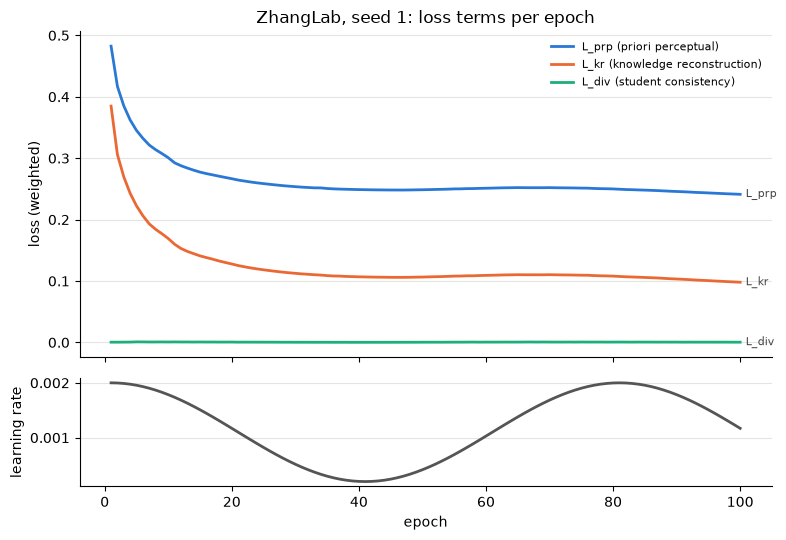

In [11]:
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']   # fixed categorical order
LOSS_TERMS = [('l_prp', 'L_prp (priori perceptual)'), ('l_kr', 'L_kr (knowledge reconstruction)'),
              ('l_div', 'L_div (student consistency)')]


def style(ax):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e4e4e0', lw=0.8)
    ax.set_axisbelow(True)


h = histories['zhanglab'][SEEDS[0]]
if h is None:
    print('no ZhangLab run yet')
else:
    fig, (ax, ax_lr) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
    for (key, label), color in zip(LOSS_TERMS, SERIES):
        ax.plot(h['epochs'], h[key], color=color, lw=2, label=label)
        ax.annotate(label.split(' ')[0], (h['epochs'][-1], h[key][-1]), xytext=(4, 0),
                    textcoords='offset points', va='center', fontsize=8, color='#444444')
    ax.set_ylabel('loss (weighted)')
    ax.set_title(f'ZhangLab, seed {SEEDS[0]}: loss terms per epoch')
    ax.legend(frameon=False, fontsize=8)
    ax_lr.plot(h['epochs'], h['lr'], color='#555555', lw=2)
    ax_lr.set_ylabel('learning rate')
    ax_lr.set_xlabel('epoch')
    for a in (ax, ax_lr):
        style(a)
    fig.tight_layout()

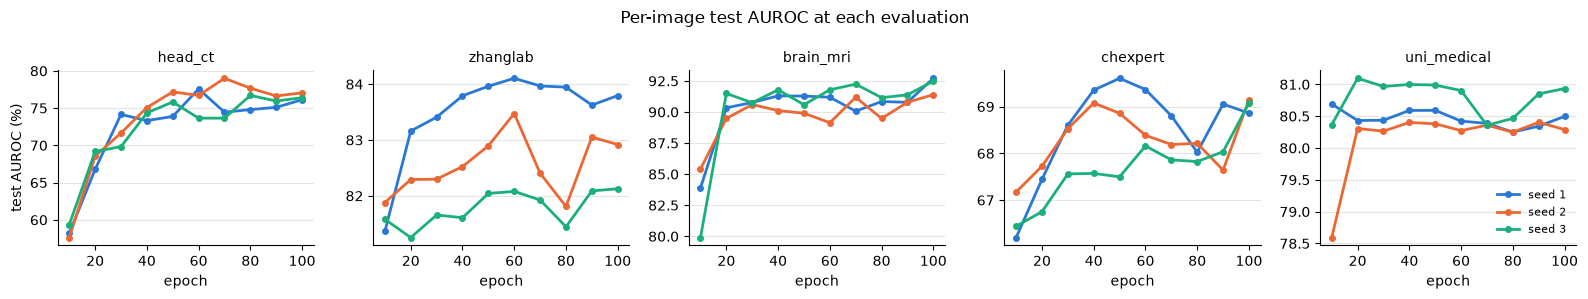

In [12]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(3.2 * len(DATASETS), 3), sharey=False)
for ax, name in zip(axes, DATASETS):
    for (seed, h), color in zip(histories[name].items(), SERIES):
        if not h or not h['evals']:
            continue
        key = 'mean' if name == 'uni_medical' else 'global'
        ax.plot([e['epoch'] for e in h['evals']], [100 * e[key]['auroc'] for e in h['evals']],
                color=color, lw=2, marker='o', ms=4, label=f'seed {seed}')
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('epoch')
    style(ax)
axes[0].set_ylabel('test AUROC (%)')
axes[-1].legend(frameon=False, fontsize=8)
fig.suptitle('Per-image test AUROC at each evaluation')
fig.tight_layout()

## 7. Ablation: diversity loss and anomaly map (Table 4)

Table 4 crosses two choices on BrainMRI: training with or without $L_{div}$, and scoring
with the teacher-student map $\cos(t_1, s_1) + \cos(t_2, s_2)$ (the PDD score) or the
student-student map $\cos(s_1, s_2)$. Every evaluation already computes both maps, so
only one extra training run is needed, with the $L_{div}$ weight set to 0 (tag
`nodiv`). The rows map to runs as follows:

| row | $L_{div}$ | map | run |
|---|---|---|---|
| M1 | yes | $\cos(s_1, s_2)$ | main run, student-student scores |
| M2 | no | $\cos(s_1, s_2)$ | `nodiv`, student-student scores |
| M3 | no | teacher-student | `nodiv`, teacher-student scores |
| Ours | yes | teacher-student | main run, teacher-student scores |

The main run is section 4's BrainMRI run for `ABLATION_SEED`. A BrainMRI run takes a few
minutes.

In [13]:
nodiv_history = run('brain_mri', ABLATION_SEED, extra_tag='nodiv', w_div=0.0)

device mps | brain_mri | train 58 | test 194 | 6 batches/epoch | decoder 30.4M params | teacher cache on
cached vs live VMamba features, max abs diff: 0.00e+00
-> /Users/toriav/Desktop/Erem/BC Cancer/Anomaly Detection/mammo-uad-2d3d/runs/pdd_brain_mri_seed1_nodiv


epoch 1/100:   0%|          | 0/6 [00:00<?, ?it/s]

epoch 2/100:   0%|          | 0/6 [00:00<?, ?it/s]

epoch 3/100:   0%|          | 0/6 [00:00<?, ?it/s]

epoch 4/100:   0%|          | 0/6 [00:00<?, ?it/s]

...

epoch 97/100:   0%|          | 0/6 [00:00<?, ?it/s]

epoch 98/100:   0%|          | 0/6 [00:00<?, ?it/s]

epoch 99/100:   0%|          | 0/6 [00:00<?, ?it/s]

epoch 100/100:   0%|          | 0/6 [00:00<?, ?it/s]

[epoch 100] loss 0.4901 (prp 0.3087 kr 0.1814 div 0.0000) | per-image AUROC 0.9140 AP 0.9691 F1 0.9530 | official-batch AUROC 0.9219
done in 3.0 min -> /Users/toriav/Desktop/Erem/BC Cancer/Anomaly Detection/mammo-uad-2d3d/runs/pdd_brain_mri_seed1_nodiv


In [14]:
PAPER_T4 = {'M1': (32.50, 81.23, 93.02), 'M2': (70.46, 97.26, 95.65),
            'M3': (93.41, 98.81, 95.93), 'Ours': (96.67, 99.51, 97.56)}
main_history = load_run('brain_mri', ABLATION_SEED)
nodiv_history = load_run('brain_mri', ABLATION_SEED, 'nodiv')

ROWS_T4 = [  # row, history, per-image key, official-batch key
    ('M1', main_history, 'per_class_ss', 'official_batch_ss'),
    ('M2', nodiv_history, 'per_class_ss', 'official_batch_ss'),
    ('M3', nodiv_history, 'per_class', 'official_batch'),
    ('Ours', main_history, 'per_class', 'official_batch'),
]


def metric_triple(e):
    return ' / '.join(f'{100 * e[k]:.2f}' for k in ('auroc', 'ap', 'f1'))


rows = []
for label, h, key, off_key in ROWS_T4:
    row = {'row': label, 'paper': ' / '.join(f'{v:.2f}' for v in PAPER_T4[label])}
    if h and h['evals']:
        get = lambda e: e[key]['brain_mri']
        best = max(h['evals'], key=lambda e: get(e)['auroc'])
        best_off = max(h['evals'], key=lambda e: e[off_key]['auroc'])
        row.update({'per-image final': metric_triple(get(h['evals'][-1])),
                    'per-image best': metric_triple(get(best)), 'best epoch': best['epoch'],
                    'official-batch final': metric_triple(h['evals'][-1][off_key]),
                    'official-batch best': metric_triple(best_off[off_key])})
    rows.append(row)
print(f'seed {ABLATION_SEED}; each cell is AUROC / AP / F1-max')
table4 = pd.DataFrame(rows).set_index('row')
table4

seed 1; each cell is AUROC / AP / F1-max


,paper,per-image final,per-image best,best epoch,official-batch final,official-batch best
row,,,,,,
M1,32.50 / 81.23 / 93.02,53.34 / 83.17 / 88.51,69.85 / 90.62 / 88.51,30,42.19 / 81.04 / 88.89,84.38 / 96.48 / 88.89
M2,70.46 / 97.26 / 95.65,71.85 / 89.16 / 90.53,74.68 / 90.85 / 90.48,40,40.62 / 77.76 / 91.43,76.56 / 94.36 / 88.89
M3,93.41 / 98.81 / 95.93,91.40 / 96.91 / 95.30,91.62 / 96.92 / 94.57,20,92.19 / 98.05 / 94.12,96.88 / 99.24 / 96.97
Ours,96.67 / 99.51 / 97.56,92.71 / 97.18 / 96.15,92.71 / 97.18 / 96.15,100,95.31 / 98.83 / 96.97,95.31 / 98.91 / 94.12


## 8. Ablation: diversity thresholds (Table 5)

Table 5 retrains with other $(\tau_{high}, \tau_{low})$ pairs on ZhangLab, HeadCT and
BrainMRI. The code's default pair $(0.30, 0.75)$ reuses section 4's runs for
`ABLATION_SEED`, so five extra runs remain: two on ZhangLab (about 45 min each), two on
HeadCT and one on BrainMRI (a few minutes each).

Table 5's numbers for the default pair (96.18 on ZhangLab, 97.31 on HeadCT) are not the
ones in Table 1 for the same setting (94.0 and 97.5), so the paper's own runs differ by
about two points on ZhangLab.

In [15]:
TAU_SETTINGS = [  # dataset, tau_high, tau_low, paper AUROC
    ('zhanglab', 0.40, 0.65, 94.52), ('zhanglab', 0.30, 0.75, 96.18), ('zhanglab', 0.75, 0.40, 95.92),
    ('head_ct', 0.30, 0.65, 96.92), ('head_ct', 0.30, 0.75, 97.31), ('head_ct', 0.75, 0.40, 96.15),
    ('brain_mri', 0.75, 0.40, 93.30),
]
DEFAULT_TAU = (PDDConfig.tau_high, PDDConfig.tau_low)


def tau_tag(tau_high, tau_low):
    return '' if (tau_high, tau_low) == DEFAULT_TAU else f'tau_h{tau_high:.2f}_l{tau_low:.2f}'


for name, tau_high, tau_low, _ in TAU_SETTINGS:
    if tau_tag(tau_high, tau_low):
        print(f'=== {name}: tau_high={tau_high}, tau_low={tau_low} ===')
        run(name, ABLATION_SEED, extra_tag=tau_tag(tau_high, tau_low), tau_high=tau_high, tau_low=tau_low)

=== zhanglab: tau_high=0.4, tau_low=0.65 ===
device mps | zhanglab | train 1249 | test 624 | 125 batches/epoch | decoder 30.4M params | teacher cache on
cached vs live VMamba features, max abs diff: 0.00e+00
-> /Users/toriav/Desktop/Erem/BC Cancer/Anomaly Detection/mammo-uad-2d3d/runs/pdd_zhanglab_seed1_tau_h0.40_l0.65


epoch 1/100:   0%|          | 0/125 [00:00<?, ?it/s]

epoch 2/100:   0%|          | 0/125 [00:00<?, ?it/s]

epoch 3/100:   0%|          | 0/125 [00:00<?, ?it/s]

epoch 4/100:   0%|          | 0/125 [00:00<?, ?it/s]

...

epoch 97/100:   0%|          | 0/6 [00:00<?, ?it/s]

epoch 98/100:   0%|          | 0/6 [00:00<?, ?it/s]

epoch 99/100:   0%|          | 0/6 [00:00<?, ?it/s]

epoch 100/100:   0%|          | 0/6 [00:00<?, ?it/s]

[epoch 100] loss 0.5827 (prp 0.3544 kr 0.2281 div 0.0002) | per-image AUROC 0.9164 AP 0.9654 F1 0.9651 | official-batch AUROC 0.9531
done in 8.2 min -> /Users/toriav/Desktop/Erem/BC Cancer/Anomaly Detection/mammo-uad-2d3d/runs/pdd_brain_mri_seed1_tau_h0.75_l0.40


In [16]:
rows = []
for name, tau_high, tau_low, paper in TAU_SETTINGS:
    h = load_run(name, ABLATION_SEED, tau_tag(tau_high, tau_low))
    row = {'dataset': name, 'tau_high': tau_high, 'tau_low': tau_low, 'paper AUROC': paper}
    if h and h['evals']:
        row.update({'AUROC final': round(100 * final_eval(h)['global']['auroc'], 2),
                    'AUROC best': round(100 * best_eval(h)['global']['auroc'], 2),
                    'official-batch AUROC final': round(100 * final_eval(h)['official_batch']['auroc'], 2),
                    'official-batch AUROC best': round(100 * best_official(h)['official_batch']['auroc'], 2)})
    rows.append(row)
print(f'seed {ABLATION_SEED}; per-image AUROC unless marked official-batch')
table5 = pd.DataFrame(rows).set_index(['dataset', 'tau_high', 'tau_low'])
table5

seed 1; per-image AUROC unless marked official-batch


paper AUROC  AUROC final  AUROC best  \
dataset   tau_high tau_low                                         
zhanglab  0.40     0.65           94.52        82.96       83.52   
          0.30     0.75           96.18        83.80       84.11   
          0.75     0.40           95.92        83.75       84.79   
head_ct   0.30     0.65           96.92        77.57       78.30   
                   0.75           97.31        76.12       77.57   
          0.75     0.40           96.15        77.62       78.40   
brain_mri 0.75     0.40           93.30        91.64       92.44   

                            official-batch AUROC final  \
dataset   tau_high tau_low                               
zhanglab  0.40     0.65                          74.35   
          0.30     0.75                          77.28   
          0.75     0.40                          76.09   
head_ct   0.30     0.65                          82.50   
                   0.75                          75.00   
          0.75     0.40                          87.50   
brain_mri 0.75     0.40                          95.31   

                            official-batch AUROC best  
dataset   tau_high tau_low                             
zhanglab  0.40     0.65                         76.52  
          0.30     0.75                         82.28  
          0.75     0.40                         79.57  
head_ct   0.30     0.65                         82.50  
                   0.75                         80.00  
          0.75     0.40                         90.00  
brain_mri 0.75     0.40                         95.31